# 11 — Final Out-of-Sample Test (January–October 2026)

**Fixed model:** OLS with archived weather forecasts and a rolling three-calendar-year training window, selected using **2025 validation only** in Notebook 10.

The project predicts Basel-Stadt next-day electricity consumption (MWh/day) from information assumed available by **12:00 Swiss time on the preceding day**. Under the professor-approved convention, only `lag_5` and older consumption observations may be used. The model is refitted once per month using observations up to **first target date minus five calendar days**.

**This notebook does not select models, tune hyperparameters, or alter the 2025-selected specification.** The 2026 holdout was already examined during project development; these corrections are for consistency, reproducibility and clearer reporting, not a new model search.

## 1. Load the frozen dataset and the previously selected configuration

In [9]:
from pathlib import Path
import json
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Support launching the notebook from repository root or code/.
ROOT = Path.cwd().resolve()
if ROOT.name == "code":
    ROOT = ROOT.parent
assert (ROOT / "data" / "processed" / "features.csv").exists(), (
    "Open this notebook from the project root or code/ directory."
)
TABLES = ROOT / "output" / "tables"
FIGURES = ROOT / "output" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Import 09_validation.py by its exact filename (no renaming required).
validation_path = ROOT / "code" / "09_validation.py"
if not validation_path.exists():
    raise FileNotFoundError(validation_path)
spec = importlib.util.spec_from_file_location("validation", validation_path)
validation = importlib.util.module_from_spec(spec)
spec.loader.exec_module(validation)
print("Shared validation module:", validation_path.name)

selection_path = TABLES / "selected_model_config.json"
if not selection_path.exists():
    raise FileNotFoundError(
        f"Missing {selection_path}. Run and verify Notebook 10 before Notebook 11."
    )
with selection_path.open("r", encoding="utf-8") as f:
    selected = json.load(f)

# Do not infer or change model choice using 2026 results.
assert selected["selected_model"] == "ols_rolling_3y", (
    "The frozen 2025-selected model differs. Investigate without using 2026 performance."
)
assert selected["training_window"] == "rolling_3y"
assert selected["train_target_cutoff_days_before_first_target"] == 5
assert selected["refit_frequency"] == "monthly"
print("2025-selected model:", selected["selected_model"])

features = pd.read_csv(
    ROOT / "data" / "processed" / "features.csv", parse_dates=["date"]
).sort_values("date").reset_index(drop=True)
validation.validate_data(features)

TEST_START = pd.Timestamp("2026-01-01")
TEST_END = pd.Timestamp("2026-10-31")
full_test_calendar = pd.date_range(TEST_START, TEST_END, freq="D")
test_data = features.loc[
    features["date"].between(TEST_START, TEST_END)
].copy()

# Evaluation dates are defined independently of model predictions.
observed_test = test_data.loc[
    test_data["consumption_mwh"].notna()
].copy()
expected_test_dates = pd.DatetimeIndex(observed_test["date"])
missing_target_dates = full_test_calendar.difference(expected_test_dates)
assert len(expected_test_dates) > 0
assert (test_data["period"] == "test").all()
print("Test period:", TEST_START.date(), "to", TEST_END.date())
print("Calendar dates:", len(full_test_calendar))
print("Observed target dates:", len(expected_test_dates))
print("Missing target dates:", len(missing_target_dates))
if len(missing_target_dates):
    print("Missing dates:", list(missing_target_dates.strftime("%Y-%m-%d")))

Shared validation module: 09_validation.py
2025-selected model: ols_rolling_3y
Data validation passed.
Total observations: 3226
Rows with missing targets: 0
Missing calendar dates within train: 0
Missing calendar dates within validation: 0
Missing calendar dates within test: 0
Test period: 2026-01-01 to 2026-10-31
Calendar dates: 304
Observed target dates: 304
Missing target dates: 0


## 2. Reproduce the selected OLS feature set and pipeline

Notebook 08 selected **16 predictors**: seven consumption lags/averages, three forecast-weather variables, two categorical calendar variables and four binary calendar variables. This section preserves that exact specification, including numeric median imputation, scaling, one-hot encoding and OLS. Learned transformations are fitted within each monthly training window.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

TARGET = "consumption_mwh"
LAG_FEATURES = [
    "lag_5", "lag_6", "lag_7", "lag_14", "lag_21", "lag_28", "lag_mean_5_11"
]
WEATHER_FEATURES = ["heating_degrees", "cooling_degrees", "forecast_precipitation"]
CATEGORICAL_FEATURES = ["weekday", "month"]
BINARY_FEATURES = [
    "is_holiday", "is_christmas_period", "lag_7_is_holiday", "lag_14_is_holiday"
]
NUMERIC_FEATURES = LAG_FEATURES + WEATHER_FEATURES
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURES) == 16 and len(FEATURES) == len(set(FEATURES))
assert not (set(FEATURES) & {"date", "period", TARGET, "baseline"})
assert set(FEATURES).issubset(features.columns)

# Exactly the same preprocessing and estimator used for expanding/rolling OLS
# in Person 3's Notebook 08.
def make_ols_pipeline():
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(
            drop="first", handle_unknown="ignore", sparse_output=False
        ), CATEGORICAL_FEATURES),
        ("binary", "passthrough", BINARY_FEATURES),
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LinearRegression()),
    ])

print("OLS features:", len(FEATURES))
print("Pipeline:", make_ols_pipeline())

OLS features: 16
Pipeline: Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['lag_5', 'lag_6', 'lag_7',
                                                   'lag_14', 'lag_21', 'lag_28',
                                                   'lag_mean_5_11',
                                                   'heating_degrees',
                                                   'cooling_degrees',
                                                   'forecast_precipitation']),
                                                 ('categorical',
                           

## 3. Verify monthly rolling-window cutoffs

The monthly model is refitted before each month's first forecast; it can train on targets no later than **the first target date minus five days**. For example, January 2026 trains through 27 December 2025. Subsequent monthly refits can use earlier 2026 observations only when they satisfy the same rule. This is walk-forward evaluation, not hyperparameter tuning.

In [11]:
test_months = pd.date_range("2026-01-01", "2026-10-01", freq="MS")
fold_records = []
for month in test_months:
    train_fold, month_fold = validation.get_rolling_fold(features, month, years=3)
    cutoff = validation.get_training_cutoff(month)
    # Do not train on missing targets; do not discard valid daily predictors.
    train_fold = train_fold.loc[train_fold[TARGET].notna()].copy()
    month_fold = month_fold.loc[month_fold[TARGET].notna()].copy()
    assert len(train_fold) and len(month_fold)
    assert train_fold["date"].max() <= cutoff
    assert train_fold["date"].max() < month_fold["date"].min()
    assert month_fold["date"].dt.to_period("M").eq(month.to_period("M")).all()
    fold_records.append({
        "forecast_month": month.strftime("%Y-%m"),
        "training_start": train_fold["date"].min(),
        "training_end": train_fold["date"].max(),
        "eligibility_cutoff": cutoff,
        "n_training": len(train_fold),
        "n_test_observed": len(month_fold),
    })
fold_information = pd.DataFrame(fold_records)
assert fold_information.loc[0, "eligibility_cutoff"] == pd.Timestamp("2025-12-27")
assert fold_information.loc[1, "eligibility_cutoff"] == pd.Timestamp("2026-01-27")
display(fold_information)
fold_information.to_csv(TABLES / "final_test_fold_information_2026.csv", index=False)

,forecast_month,training_start,training_end,eligibility_cutoff,n_training,n_test_observed
0,2026-01,2022-12-28,2025-12-27,2025-12-27,1096,31
1,2026-02,2023-01-28,2026-01-27,2026-01-27,1096,28
2,2026-03,2023-02-25,2026-02-24,2026-02-24,1096,31
3,2026-04,2023-03-28,2026-03-27,2026-03-27,1096,30
4,2026-05,2023-04-27,2026-04-26,2026-04-26,1096,31
5,2026-06,2023-05-28,2026-05-27,2026-05-27,1096,30
6,2026-07,2023-06-27,2026-06-26,2026-06-26,1096,31
7,2026-08,2023-07-28,2026-07-27,2026-07-27,1096,31
8,2026-09,2023-08-28,2026-08-27,2026-08-27,1096,30
9,2026-10,2023-09-27,2026-09-26,2026-09-26,1096,31


## 4. Generate the fixed model's 2026 predictions

The same OLS pipeline is refitted once per month. Its feature transformations are learned exclusively on eligible training observations. All predictions correspond to the target date and use features already prepared in `features.csv`.

In [12]:
monthly_predictions = []
for month in test_months:
    train_fold, test_fold = validation.get_rolling_fold(features, month, years=3)
    train_fold = train_fold.loc[train_fold[TARGET].notna()].copy()
    test_fold = test_fold.loc[test_fold[TARGET].notna()].copy()
    model = make_ols_pipeline()
    model.fit(train_fold[FEATURES], train_fold[TARGET])
    predicted = model.predict(test_fold[FEATURES])
    assert np.isfinite(predicted).all()
    monthly_predictions.append(pd.DataFrame({
        "date": test_fold["date"].to_numpy(),
        "model": selected["selected_model"],
        "forecast_month": month.strftime("%Y-%m"),
        "validation_month": month.strftime("%Y-%m"),
        "actual_mwh": test_fold[TARGET].to_numpy(),
        "predicted_mwh": predicted,
    }))
    print(f"{month:%Y-%m}: fitted {len(train_fold)} observations, "
          f"predicted {len(test_fold)} observed test dates")

test_predictions = pd.concat(monthly_predictions, ignore_index=True)
test_predictions["prediction_error_mwh"] = (
    test_predictions["actual_mwh"] - test_predictions["predicted_mwh"]
)
test_predictions["absolute_error_mwh"] = test_predictions["prediction_error_mwh"].abs()
assert len(test_predictions) == len(expected_test_dates)
assert test_predictions["date"].is_unique
print("Total final test predictions:", len(test_predictions))
display(test_predictions.head())

2026-01: fitted 1096 observations, predicted 31 observed test dates
2026-02: fitted 1096 observations, predicted 28 observed test dates
2026-03: fitted 1096 observations, predicted 31 observed test dates
2026-04: fitted 1096 observations, predicted 30 observed test dates
2026-05: fitted 1096 observations, predicted 31 observed test dates
2026-06: fitted 1096 observations, predicted 30 observed test dates
2026-07: fitted 1096 observations, predicted 31 observed test dates
2026-08: fitted 1096 observations, predicted 31 observed test dates
2026-09: fitted 1096 observations, predicted 30 observed test dates
2026-10: fitted 1096 observations, predicted 31 observed test dates
Total final test predictions: 304


,date,model,forecast_month,validation_month,actual_mwh,predicted_mwh,prediction_error_mwh,absolute_error_mwh
0,2026-01-01,ols_rolling_3y,2026-01,2026-01,2985.107967,2988.037130,-2.929163,2.929163
1,2026-01-02,ols_rolling_3y,2026-01,2026-01,3320.102407,3482.218375,-162.115968,162.115968
2,2026-01-03,ols_rolling_3y,2026-01,2026-01,3165.191591,3071.288227,93.903364,93.903364
3,2026-01-04,ols_rolling_3y,2026-01,2026-01,3036.920826,2914.556289,122.364537,122.364537
4,2026-01-05,ols_rolling_3y,2026-01,2026-01,3675.001032,3513.590009,161.411023,161.411023


## 5. Validate coverage, target alignment and final error metrics

Use the shared `09_validation.py` checks with the **observed frozen-snapshot target dates**, not an assumed complete 2026 calendar. No model is allowed to exclude additional difficult dates silently. Error is always **actual minus predicted**.

In [13]:
validation.validate_predictions(test_predictions, expected_year=2026)
validation.validate_actual_values(test_predictions, features)
validation.validate_prediction_coverage(
    test_predictions, expected_dates=expected_test_dates
)

test_metrics = validation.compute_metrics(
    test_predictions["actual_mwh"], test_predictions["predicted_mwh"]
)
print("Selected model — final holdout 2026")
print("Observed test dates:", test_metrics["n_days"])
print(f"MAE: {test_metrics['mae_mwh']:.2f} MWh/day")
print(f"RMSE: {test_metrics['rmse_mwh']:.2f} MWh/day")
print(f"Mean signed error: {test_metrics['mean_error_mwh']:+.2f} MWh/day")

Prediction validation passed.
Models: 1
Predictions: 304
Actual consumption values match features.csv.
Prediction coverage validation passed.
Models checked: 1
Expected dates: 304
Selected model — final holdout 2026
Observed test dates: 304
MAE: 72.59 MWh/day
RMSE: 94.63 MWh/day
Mean signed error: +8.42 MWh/day


## 6. Compare with the pre-specified historical baseline

The group baseline is the previous same weekday (`lag_7`), with successive fallback to `lag_14`, `lag_21`, and `lag_28` when earlier observations are missing. Person 1 already stored this agreed prediction in `features.csv` as `baseline`. We reuse it rather than simplifying the benchmark to `lag_7` alone. A missing baseline prediction after all candidate fallbacks must be reported and resolved rather than silently dropped.

In [14]:
baseline_predictions = observed_test[["date", TARGET, "baseline"]].copy()
# Use the same observed target dates, in the same order, for both methods.
baseline_predictions = baseline_predictions.sort_values("date").reset_index(drop=True)
assert baseline_predictions["date"].equals(
    test_predictions.sort_values("date").reset_index(drop=True)["date"]
)
if baseline_predictions["baseline"].isna().any():
    missing_baseline = baseline_predictions.loc[
        baseline_predictions["baseline"].isna(), "date"
    ]
    raise ValueError(
        "Some observed test dates have no baseline prediction. "
        "Agree on a historical-information-only fallback before comparing: "
        + str(list(missing_baseline.dt.strftime("%Y-%m-%d")))
    )
# Check baseline follows Person 1's priority rule on observed dates.
expected_baseline = features[["date", "lag_7", "lag_14", "lag_21", "lag_28"]].copy()
expected_baseline["expected"] = (
    expected_baseline["lag_7"]
    .fillna(expected_baseline["lag_14"])
    .fillna(expected_baseline["lag_21"])
    .fillna(expected_baseline["lag_28"])
)
baseline_check = baseline_predictions.merge(
    expected_baseline[["date", "expected"]], on="date", validate="one_to_one"
)
assert np.allclose(baseline_check["baseline"], baseline_check["expected"],
                   rtol=0, atol=1e-6)

baseline_metrics = validation.compute_metrics(
    baseline_predictions[TARGET], baseline_predictions["baseline"]
)
comparison = pd.DataFrame([
    {"model": "baseline_lag7_with_fallback", **baseline_metrics},
    {"model": selected["selected_model"], **test_metrics},
])
mae_improvement_pct = 100 * (
    1 - test_metrics["mae_mwh"] / baseline_metrics["mae_mwh"]
)
print(f"MAE reduction relative to baseline: {mae_improvement_pct:.2f}%")
display(comparison.round(2))

MAE reduction relative to baseline: 55.05%


,model,n_days,mae_mwh,rmse_mwh,mean_error_mwh
0,baseline_lag7_with_fallback,304,161.48,226.87,7.03
1,ols_rolling_3y,304,72.59,94.63,8.42


## 7. Final test visualizations

The following plots show the daily fit, monthly variation in forecast errors and the pre-specified comparison with the baseline. They are **descriptive**, not inputs to new model selection.

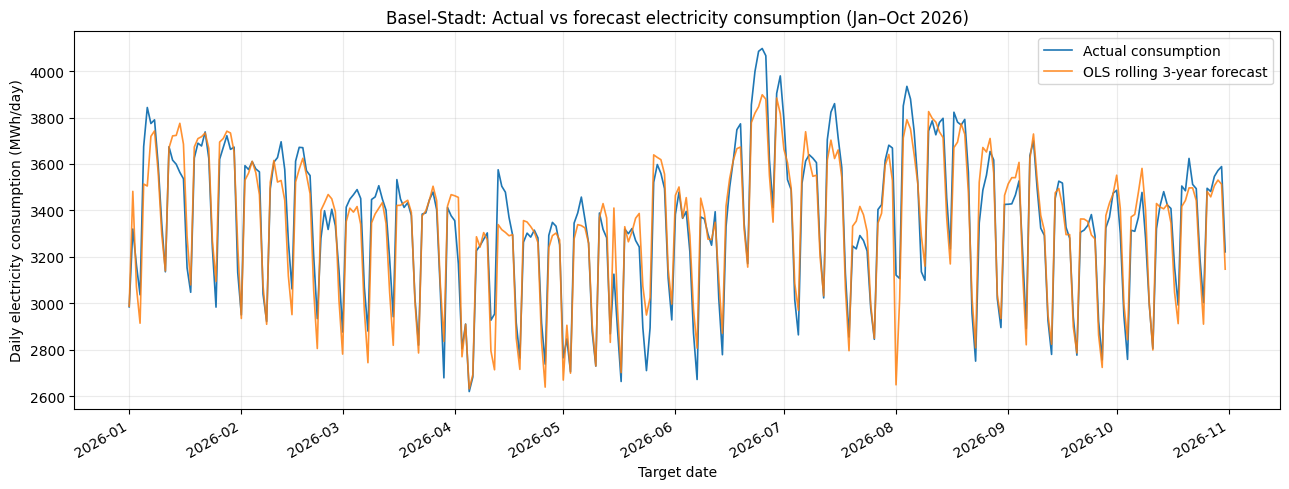

In [15]:
# Actual and selected-model forecast over the test horizon
plot_pred = test_predictions.sort_values("date")
fig_actual, ax = plt.subplots(figsize=(13, 5))
ax.plot(plot_pred["date"], plot_pred["actual_mwh"],
        label="Actual consumption", linewidth=1.2)
ax.plot(plot_pred["date"], plot_pred["predicted_mwh"],
        label="OLS rolling 3-year forecast", linewidth=1.2, alpha=0.85)
ax.set(title="Basel-Stadt: Actual vs forecast electricity consumption (Jan–Oct 2026)",
       xlabel="Target date", ylabel="Daily electricity consumption (MWh/day)")
ax.legend()
ax.grid(alpha=0.25)
fig_actual.autofmt_xdate()
fig_actual.tight_layout()
fig_actual.savefig(FIGURES / "final_test_actual_vs_predicted_2026.png", dpi=300, bbox_inches="tight")
plt.show()

,month,n_days,mae_mwh,rmse_mwh,mean_error_mwh
0,2026-01,31,79.43,107.28,-19.64
1,2026-02,28,74.93,91.04,40.52
2,2026-03,31,61.13,76.51,35.40
3,2026-04,30,76.56,107.42,28.97
4,2026-05,31,76.12,100.76,-44.79
5,2026-06,30,79.63,100.38,19.16
6,2026-07,31,73.61,88.44,8.94
7,2026-08,31,93.64,125.60,22.45
8,2026-09,30,47.42,55.43,-9.41
9,2026-10,31,63.16,72.98,6.16


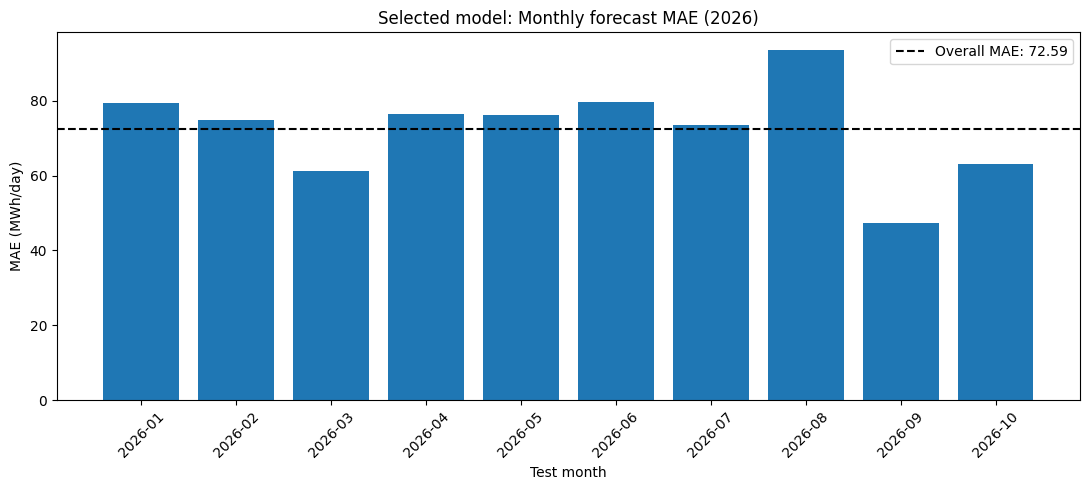

In [16]:
# Monthly metrics are calculated from daily errors, not averages of month-level scores.
monthly_test = (test_predictions.assign(
    month=test_predictions["date"].dt.strftime("%Y-%m")
).groupby("month").agg(
    n_days=("date", "size"),
    mae_mwh=("absolute_error_mwh", "mean"),
    rmse_mwh=("prediction_error_mwh", lambda x: np.sqrt(np.mean(np.square(x)))),
    mean_error_mwh=("prediction_error_mwh", "mean"),
).reset_index())
display(monthly_test.round(2))
fig_month, ax = plt.subplots(figsize=(11, 5))
ax.bar(monthly_test["month"], monthly_test["mae_mwh"])
ax.axhline(test_metrics["mae_mwh"], color="black", linestyle="--",
           label=f"Overall MAE: {test_metrics['mae_mwh']:.2f}")
ax.set(title="Selected model: Monthly forecast MAE (2026)",
       xlabel="Test month", ylabel="MAE (MWh/day)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig_month.tight_layout()
fig_month.savefig(FIGURES / "final_test_monthly_mae_2026.png", dpi=300, bbox_inches="tight")
plt.show()

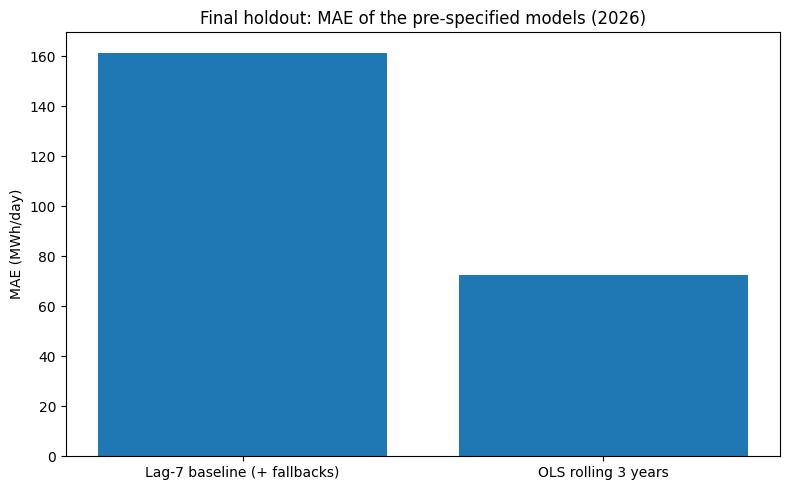

In [17]:
# Fixed selected model versus same-day baseline
fig_comparison, ax = plt.subplots(figsize=(8, 5))
ax.bar(["Lag-7 baseline (+ fallbacks)", "OLS rolling 3 years"],
       [baseline_metrics["mae_mwh"], test_metrics["mae_mwh"]])
ax.set(title="Final holdout: MAE of the pre-specified models (2026)",
       ylabel="MAE (MWh/day)")
fig_comparison.tight_layout()
fig_comparison.savefig(FIGURES / "final_test_model_comparison_2026.png",
                       dpi=300, bbox_inches="tight")
plt.show()

## 8. Export reproducible final test results

Save the fixed model's daily test predictions, metrics, month-by-month diagnostics, and training-window boundaries. They are derived exclusively from the existing frozen data and the locked 2025-selected model.

In [18]:
test_predictions.to_csv(TABLES / "final_test_predictions_2026.csv", index=False)
comparison.to_csv(TABLES / "final_test_metrics_2026.csv", index=False)
monthly_test.to_csv(TABLES / "final_test_monthly_metrics_2026.csv", index=False)
# Fold boundaries already saved in Section 3.
print("Saved daily predictions, metrics, monthly diagnostics and figures to output/.")

Saved daily predictions, metrics, monthly diagnostics and figures to output/.


## 9. Interpretation and limitations

Run the final code cell below to generate a conclusion from the **actual executed results** rather than hard-coded previously reported numbers.

The holdout is January–October 2026 (ten months), whereas validation covered all of 2025. The project relies on a frozen historical data snapshot, the conservative target-relative `lag_5` data availability rule, and archived weather forecasts. These assumptions do not independently verify the historical publication/issuance timestamp of every predictor. Changes in electricity consumption patterns should be discussed as forecast-relevant differences, **not causal effects of policy campaigns**.

**After seeing the holdout results, do not change the model, preprocessing, training-window length, or hyperparameters to improve its score.**

In [19]:
val_mae = None
validation_comparison_path = TABLES / "final_validation_comparison.csv"
if validation_comparison_path.exists():
    previous = pd.read_csv(validation_comparison_path)
    match = previous.loc[previous["model"] == selected["selected_model"]]
    if len(match) == 1 and "MAE" in match:
        val_mae = float(match["MAE"].iloc[0])

print("FINAL PROJECT RESULT — selected using 2025 validation")
print("Selected model: OLS with weather, rolling 3-year training window")
print("Final holdout: January–October 2026")
print(f"Evaluated observed days: {test_metrics['n_days']}")
print(f"Test MAE: {test_metrics['mae_mwh']:.2f} MWh/day")
print(f"Test RMSE: {test_metrics['rmse_mwh']:.2f} MWh/day")
print(f"Test mean signed error: {test_metrics['mean_error_mwh']:+.2f} MWh/day")
print(f"Lag-7 baseline MAE: {baseline_metrics['mae_mwh']:.2f} MWh/day")
print(f"MAE reduction relative to baseline: {mae_improvement_pct:.2f}%")
if val_mae is not None:
    print(f"2025 validation MAE (different calendar period): {val_mae:.2f} MWh/day")
print("Interpretation is conditional on the documented historical availability assumptions.")

FINAL PROJECT RESULT — selected using 2025 validation
Selected model: OLS with weather, rolling 3-year training window
Final holdout: January–October 2026
Evaluated observed days: 304
Test MAE: 72.59 MWh/day
Test RMSE: 94.63 MWh/day
Test mean signed error: +8.42 MWh/day
Lag-7 baseline MAE: 161.48 MWh/day
MAE reduction relative to baseline: 55.05%
2025 validation MAE (different calendar period): 74.64 MWh/day
Interpretation is conditional on the documented historical availability assumptions.
